# Task 2 — Player Segment Classification

This notebook explores the labeled player data and trains a first CatBoost multiclass baseline. It uses a stratified holdout split from `train.csv` for validation; `test.csv` is not loaded or used for fitting. The provided Task 2 data has no separate validation CSV.

The project brief calls the metric F1 without specifying its averaging mode, so this notebook reports both macro and weighted F1. Verify the official Kaggle scoring mode before choosing a final model.

**Labels:** 0 Casual · 1 Grinder · 2 Social · 3 Whale.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TARGET = "segment"
CLASS_NAMES = {0: "Casual", 1: "Grinder", 2: "Social", 3: "Whale"}
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "train.csv").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
ASSETS_DIR = PROJECT_DIR / "assets"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print(f"Project directory: {PROJECT_DIR.resolve()}")

Project directory: C:\Users\Gunte\Workspace\Workspace\works\CPE\ml00x\task2


In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
assert TARGET in train.columns, f"Missing target column: {TARGET}"
assert set(train[TARGET].dropna().unique()).issubset(CLASS_NAMES), "Unexpected target labels"

print(f"Labeled training data: {train.shape[0]:,} rows × {train.shape[1]} columns")
print(f"Predictor columns, including player_id: {train.shape[1] - 1}")
display(train.head())

Labeled training data: 104,000 rows × 46 columns
Predictor columns, including player_id: 45


,player_id,play_frequency,avg_session_duration,total_playtime_hours,login_streak,days_since_last_login,total_spending_thb,avg_monthly_spending,spending_frequency,friend_count,...,platform,device_type,payment_method,language,account_status,player_type_tag,engagement_level,loyalty_tier,skill_tier,segment
0,P097760,21.076212,NaN,NaN,97.0,67.103422,72431.180593,3646.197510,17.712461,NaN,...,PC,Phone,Card,NaN,Dormant,Collector,Low,Platinum,Diamond,2
1,P118291,7.909114,197.315042,976.440940,103.0,50.869211,50422.023411,4286.361523,7.755040,91.0,...,Mobile,Laptop,Card,ES,Active,Social,High,Silver,NaN,3
2,P036138,2.520035,23.604288,1878.417029,61.0,74.477188,9970.156942,167.952963,36.403912,53.0,...,Console,Tablet,Card,JP,Dormant,Collector,Mid,Bronze,Platinum,0
3,P096415,15.678080,27.094268,678.992690,33.0,77.549945,17555.692929,1083.661525,44.751112,91.0,...,PC,Laptop,Card,KR,Active,Collector,Low,Platinum,Platinum,2
4,P045208,4.298657,NaN,1533.178518,73.0,79.350344,34814.668734,3773.956964,1.732425,91.0,...,PC,Desktop,Wallet,JP,Active,Casual,Mid,NaN,Bronze,0


,players,share
Casual,40934,39.4%
Grinder,26034,25.0%
Social,21014,20.2%
Whale,16018,15.4%


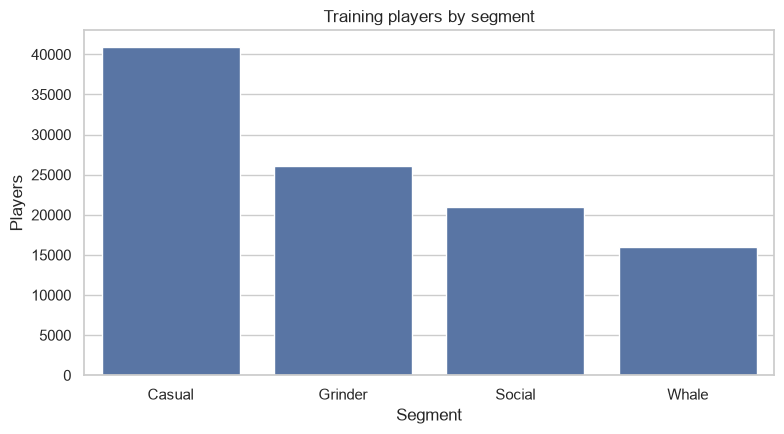

In [3]:
class_counts = train[TARGET].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
class_summary = pd.DataFrame({"players": class_counts, "share": class_counts / class_counts.sum()})
class_summary.index = [CLASS_NAMES[label] for label in class_summary.index]
display(class_summary.style.format({"share": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=[CLASS_NAMES[label] for label in class_counts.index], y=class_counts.values, ax=ax)
ax.set(title="Training players by segment", xlabel="Segment", ylabel="Players")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "segment-class-distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
missing_summary = (
    train.drop(columns=[TARGET])
    .isna()
    .mean()
    .loc[lambda values: values.gt(0)]
    .sort_values(ascending=False)
    .rename("missing_fraction")
    .to_frame()
)
display(missing_summary.head(20).style.format("{:.1%}"))

display(train.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))

,missing_fraction
payment_method,30.7%
region,26.1%
account_status,7.8%
platform,7.8%
item_type_preference_social,7.8%
item_type_preference_performance,7.8%
random_metric_1,7.8%
skill_tier,7.8%
random_metric_2,7.8%
avg_match_length,7.8%


,column_count
dtype,
float64,34
str,11
int64,1


## Stratified validation baseline

`player_id` is excluded because it is an identifier, not a behavioral feature. CatBoost handles numeric missing values natively; missing categorical values are replaced with an explicit sentinel. The holdout is stratified and used only for validation.

In [5]:
X = train.drop(columns=[TARGET, "player_id"], errors="ignore").copy()
y = train[TARGET].astype(int)
categorical_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
X[categorical_features] = X[categorical_features].fillna("__MISSING__").astype(str)

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Train split: {len(X_train):,}; validation split: {len(X_valid):,}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Train split: 83,200; validation split: 20,800
Categorical features (10): ['region', 'platform', 'device_type', 'payment_method', 'language', 'account_status', 'player_type_tag', 'engagement_level', 'loyalty_tier', 'skill_tier']


In [6]:
model = CatBoostClassifier(
    iterations=300,
    depth=7,
    learning_rate=0.08,
    loss_function="MultiClass",
    eval_metric="MultiClass",
    random_seed=RANDOM_STATE,
    allow_writing_files=False,
    thread_count=-1,
    verbose=False,
)
model.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=40,
    verbose=False,
)
print(f"Best iteration: {model.get_best_iteration()}")

Best iteration: 299


In [7]:
valid_predictions = model.predict(X_valid).reshape(-1).astype(int)
validation_scores = pd.DataFrame(
    {
        "F1": [
            f1_score(y_valid, valid_predictions, average="macro"),
            f1_score(y_valid, valid_predictions, average="weighted"),
        ]
    },
    index=["Macro", "Weighted"],
)
display(validation_scores)

report = classification_report(
    y_valid,
    valid_predictions,
    labels=list(CLASS_NAMES),
    target_names=list(CLASS_NAMES.values()),
    output_dict=True,
    zero_division=0,
)
display(pd.DataFrame(report).T.style.format("{:.3f}"))

,F1
Macro,0.746242
Weighted,0.760576


,precision,recall,f1-score,support
Casual,0.781,0.859,0.818,8187.000
Grinder,0.740,0.730,0.735,5207.000
Social,0.738,0.678,0.707,4203.000
Whale,0.777,0.679,0.725,3203.000
accuracy,0.763,0.763,0.763,0.763
macro avg,0.759,0.737,0.746,20800.000
weighted avg,0.762,0.763,0.761,20800.000


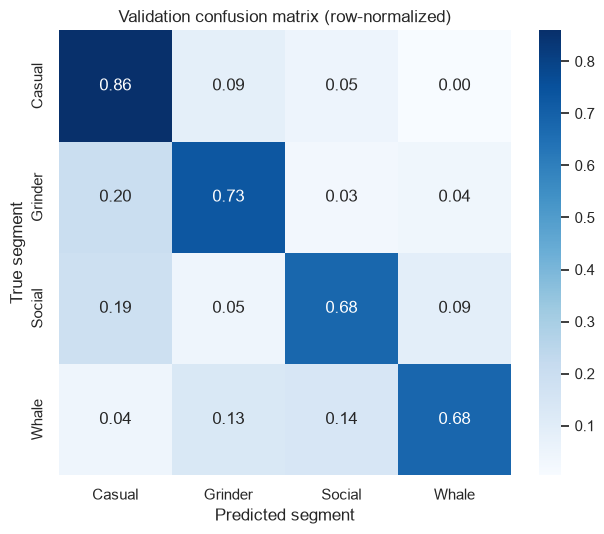

In [8]:
matrix = confusion_matrix(y_valid, valid_predictions, labels=list(CLASS_NAMES), normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(
    matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=list(CLASS_NAMES.values()),
    yticklabels=list(CLASS_NAMES.values()),
    ax=ax,
)
ax.set(
    title="Validation confusion matrix (row-normalized)",
    xlabel="Predicted segment",
    ylabel="True segment",
)
fig.tight_layout()
fig.savefig(ASSETS_DIR / "segment-validation-confusion-matrix.png", dpi=300, bbox_inches="tight")
plt.show()

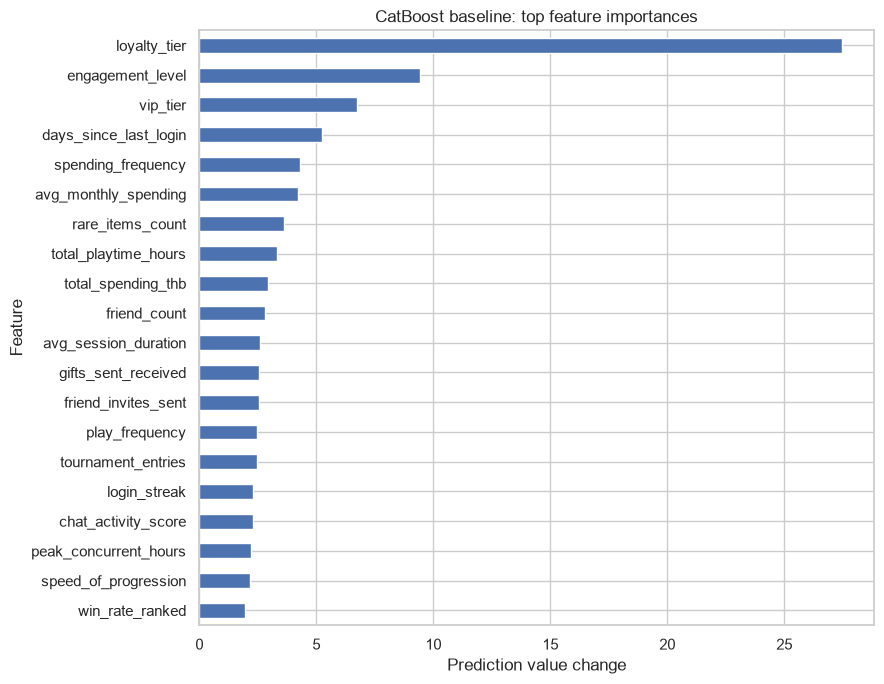

In [9]:
importance = (
    pd.Series(model.feature_importances_, index=model.feature_names_).sort_values().tail(20)
)
fig, ax = plt.subplots(figsize=(9, 7))
importance.plot.barh(ax=ax)
ax.set(
    title="CatBoost baseline: top feature importances",
    xlabel="Prediction value change",
    ylabel="Feature",
)
fig.tight_layout()
fig.savefig(ASSETS_DIR / "segment-feature-importance.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretation and next steps

This is a reproducible first benchmark, not a tuned final model. Compare models and feature engineering with the same stratified folds, optimize the F1 averaging mode used by the competition, and only then refit on all labeled training data before producing test predictions. The generated figures are saved under `assets/` at 300 dpi.